# Black Sigatoka EDA

Cavendish banana environmental risk study, Bingiriya, Sri Lanka. Labels are simulated risk scores, not confirmed disease observations. No cleaning or model training is performed.

## Setup

Import the libraries used in this EDA.

In [1]:
from pathlib import Path
from itertools import combinations
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'datasets/black_sigatoka').is_dir())
DATA = ROOT / 'datasets/black_sigatoka'
OUT = ROOT / 'reports/black_sigatoka'
OUT.mkdir(parents=True, exist_ok=True)
FILES = {s: DATA / f'BS_FULL_FEATURE_SIMULATED_{s}.csv' for s in ['train', 'validation', 'test']}
FILES['historical'] = DATA / 'BS_FULL_FEATURE_HISTORICAL_NASA.csv'
source_hashes = {s: hashlib.sha256(p.read_bytes()).hexdigest() for s, p in FILES.items()}
datasets = {s: pd.read_csv(p) for s, p in FILES.items()}
train = datasets['train']
historical = datasets['historical']
LEVELS = ['No Risk', 'Low', 'Moderate', 'High']
INPUTS = ['air_temp_c', 'estimated_leaf_wet', 'consecutive_wetness_hours']
ENV = ['air_temp_c', 'relative_humidity_pct', 'rainfall_mm_hr', 'dew_point_c',
       'dew_point_depression_c', 'wind_speed_m_s', 'solar_radiation_mj_hr',
       'estimated_leaf_wet', 'consecutive_wetness_hours', 'wet_hours_previous_24h',
       'wet_hours_previous_72h', 'rain_previous_24h_mm', 'mean_temp_previous_24h_c',
       'mean_rh_previous_24h_pct', 'canopy_temperature_c']
assert all(set(ENV + ['risk_score', 'risk_level']).issubset(d.columns) for d in datasets.values())
LABELS = {'air_temp_c': 'Air temperature (°C)', 'relative_humidity_pct': 'Relative humidity (%)',
          'rainfall_mm_hr': 'Rainfall (mm/h)', 'estimated_leaf_wet': 'Estimated leaf wetness (0=dry, 1=wet)',
          'consecutive_wetness_hours': 'Consecutive wetness (hours)', 'risk_score': 'Simulated risk score (0–100)'}
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 30)
figures = []
def table(df, name):
    df.to_csv(OUT / f'{name}.csv', index=True)
    display(df)
def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f'{name}.png', dpi=160, bbox_inches='tight')
    figures.append(f'{name}.png')
    plt.show()
    plt.close(fig)
print('Python:', sys.executable)
print('Data directory:', DATA)
print('Outputs:', OUT)

Python: C:\Users\HP\Desktop\ML training\.venv\Scripts\python.exe
Data directory: C:\Users\HP\Desktop\ML training\datasets\black_sigatoka
Outputs: C:\Users\HP\Desktop\ML training\reports\black_sigatoka


## 1. Dataset overview

Load all four CSVs and inspect shapes, columns, data types, sample rows, and provenance.

In [3]:
overview = pd.DataFrame({s: {'rows': len(d), 'columns': len(d.columns)} for s, d in datasets.items()}).T
table(overview, 'dataset_overview')
for s, d in datasets.items():
    display(Markdown(f'### {s.title()} — {FILES[s].name}'))
    print('Columns:', d.columns.tolist())
    display(d.dtypes.rename('dtype').to_frame())
    display(d.head(5))
    for c in ['record_type', 'temperature_input_type', 'wetness_estimation_method', 'label_source', 'split']:
        print(c, ':', d[c].value_counts(dropna=False).to_dict())

,rows,columns
train,4200,25
validation,900,25
test,900,25
historical,26304,25


### Train — BS_FULL_FEATURE_SIMULATED_train.csv

Columns: ['scenario_id', 'record_type', 'timestamp_utc', 'air_temp_c', 'relative_humidity_pct', 'rainfall_mm_hr', 'dew_point_c', 'dew_point_depression_c', 'wind_speed_m_s', 'solar_radiation_mj_hr', 'estimated_leaf_wet', 'consecutive_wetness_hours', 'wet_hours_previous_24h', 'wet_hours_previous_72h', 'rain_previous_24h_mm', 'mean_temp_previous_24h_c', 'mean_rh_previous_24h_pct', 'canopy_temperature_c', 'temperature_input_type', 'wetness_estimation_method', 'risk_score', 'risk_level', 'label_source', 'split', 'weather_analogue_timestamp_utc']


,dtype
scenario_id,str
record_type,str
timestamp_utc,float64
air_temp_c,float64
relative_humidity_pct,float64
rainfall_mm_hr,float64
dew_point_c,float64
dew_point_depression_c,float64
wind_speed_m_s,float64
solar_radiation_mj_hr,float64


,scenario_id,record_type,timestamp_utc,air_temp_c,relative_humidity_pct,rainfall_mm_hr,dew_point_c,dew_point_depression_c,wind_speed_m_s,solar_radiation_mj_hr,estimated_leaf_wet,consecutive_wetness_hours,wet_hours_previous_24h,wet_hours_previous_72h,rain_previous_24h_mm,mean_temp_previous_24h_c,mean_rh_previous_24h_pct,canopy_temperature_c,temperature_input_type,wetness_estimation_method,risk_score,risk_level,label_source,split,weather_analogue_timestamp_utc
0,SIM_HIGH_0655,SYNTHETIC_SCENARIO_NOT_MEASURED,NaN,29.601,98.79,1.11,29.39,0.21,4.72,0.098,1,95,24,72,NaN,NaN,NaN,NaN,AIR_TEMPERATURE_PROXY,SCENARIO_SET_RH_GE_98_WET_ELSE_DRY; NOT SENSOR,94.9136,High,PROJECT_ADAPTED_BEBBER_WEIBULL_WET_SPELL; NOT ...,train,2024-10-13 06:00:00+00:00
1,SIM_NORISK_1070,SYNTHETIC_SCENARIO_NOT_MEASURED,NaN,23.794,57.02,0.00,14.77,9.02,3.46,0.000,0,0,0,0,NaN,NaN,NaN,NaN,AIR_TEMPERATURE_PROXY,SCENARIO_SET_RH_GE_98_WET_ELSE_DRY; NOT SENSOR,0.0000,No Risk,PROJECT_ADAPTED_BEBBER_WEIBULL_WET_SPELL; NOT ...,train,2023-01-24 22:00:00+00:00
2,SIM_NORISK_1054,SYNTHETIC_SCENARIO_NOT_MEASURED,NaN,30.865,87.30,0.00,28.51,2.35,0.82,1.310,0,0,0,0,NaN,NaN,NaN,NaN,AIR_TEMPERATURE_PROXY,SCENARIO_SET_RH_GE_98_WET_ELSE_DRY; NOT SENSOR,0.0000,No Risk,PROJECT_ADAPTED_BEBBER_WEIBULL_WET_SPELL; NOT ...,train,2024-05-11 04:00:00+00:00
3,SIM_NORISK_0522,SYNTHETIC_SCENARIO_NOT_MEASURED,NaN,33.100,82.68,0.00,29.76,3.34,0.54,2.610,0,0,0,0,NaN,NaN,NaN,NaN,AIR_TEMPERATURE_PROXY,SCENARIO_SET_RH_GE_98_WET_ELSE_DRY; NOT SENSOR,0.0000,No Risk,PROJECT_ADAPTED_BEBBER_WEIBULL_WET_SPELL; NOT ...,train,2024-09-29 08:00:00+00:00
4,SIM_NORISK_0363,SYNTHETIC_SCENARIO_NOT_MEASURED,NaN,22.779,65.40,0.00,15.95,6.83,4.21,0.000,0,0,0,0,NaN,NaN,NaN,NaN,AIR_TEMPERATURE_PROXY,SCENARIO_SET_RH_GE_98_WET_ELSE_DRY; NOT SENSOR,0.0000,No Risk,PROJECT_ADAPTED_BEBBER_WEIBULL_WET_SPELL; NOT ...,train,2022-02-02 15:00:00+00:00


...

### Historical — BS_FULL_FEATURE_HISTORICAL_NASA.csv

Columns: ['scenario_id', 'record_type', 'timestamp_utc', 'air_temp_c', 'relative_humidity_pct', 'rainfall_mm_hr', 'dew_point_c', 'dew_point_depression_c', 'wind_speed_m_s', 'solar_radiation_mj_hr', 'estimated_leaf_wet', 'consecutive_wetness_hours', 'wet_hours_previous_24h', 'wet_hours_previous_72h', 'rain_previous_24h_mm', 'mean_temp_previous_24h_c', 'mean_rh_previous_24h_pct', 'canopy_temperature_c', 'temperature_input_type', 'wetness_estimation_method', 'risk_score', 'risk_level', 'label_source', 'split', 'weather_analogue_timestamp_utc']


,dtype
scenario_id,str
record_type,str
timestamp_utc,str
air_temp_c,float64
relative_humidity_pct,float64
rainfall_mm_hr,float64
dew_point_c,float64
dew_point_depression_c,float64
wind_speed_m_s,float64
solar_radiation_mj_hr,float64


,scenario_id,record_type,timestamp_utc,air_temp_c,relative_humidity_pct,rainfall_mm_hr,dew_point_c,dew_point_depression_c,wind_speed_m_s,solar_radiation_mj_hr,estimated_leaf_wet,consecutive_wetness_hours,wet_hours_previous_24h,wet_hours_previous_72h,rain_previous_24h_mm,mean_temp_previous_24h_c,mean_rh_previous_24h_pct,canopy_temperature_c,temperature_input_type,wetness_estimation_method,risk_score,risk_level,label_source,split,weather_analogue_timestamp_utc
0,NASA_00000,NASA_GRIDDED_WEATHER_WITH_ESTIMATED_WETNESS,2022-01-01 00:00:00+00:00,24.11,95.45,0.24,23.34,0.77,2.92,0.00,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NASA_2M_AIR_TEMPERATURE_PROXY,RH>=98pct OR hourly precipitation>=1mm (projec...,0.0,No Risk,Bebber2019 Weibull temperature-dependent wet-s...,excluded_warmup,NaN
1,NASA_00001,NASA_GRIDDED_WEATHER_WITH_ESTIMATED_WETNESS,2022-01-01 01:00:00+00:00,24.85,93.61,0.25,23.76,1.09,3.51,0.25,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NASA_2M_AIR_TEMPERATURE_PROXY,RH>=98pct OR hourly precipitation>=1mm (projec...,0.0,No Risk,Bebber2019 Weibull temperature-dependent wet-s...,excluded_warmup,NaN
2,NASA_00002,NASA_GRIDDED_WEATHER_WITH_ESTIMATED_WETNESS,2022-01-01 02:00:00+00:00,25.92,90.95,0.26,24.35,1.57,4.04,1.00,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NASA_2M_AIR_TEMPERATURE_PROXY,RH>=98pct OR hourly precipitation>=1mm (projec...,0.0,No Risk,Bebber2019 Weibull temperature-dependent wet-s...,excluded_warmup,NaN
3,NASA_00003,NASA_GRIDDED_WEATHER_WITH_ESTIMATED_WETNESS,2022-01-01 03:00:00+00:00,27.18,85.70,0.26,24.61,2.57,4.53,1.80,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NASA_2M_AIR_TEMPERATURE_PROXY,RH>=98pct OR hourly precipitation>=1mm (projec...,0.0,No Risk,Bebber2019 Weibull temperature-dependent wet-s...,excluded_warmup,NaN
4,NASA_00004,NASA_GRIDDED_WEATHER_WITH_ESTIMATED_WETNESS,2022-01-01 04:00:00+00:00,28.22,80.42,0.30,24.55,3.67,4.59,2.48,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NASA_2M_AIR_TEMPERATURE_PROXY,RH>=98pct OR hourly precipitation>=1mm (projec...,0.0,No Risk,Bebber2019 Weibull temperature-dependent wet-s...,excluded_warmup,NaN


record_type : {'NASA_GRIDDED_WEATHER_WITH_ESTIMATED_WETNESS': 26304}
temperature_input_type : {'NASA_2M_AIR_TEMPERATURE_PROXY': 26304}
wetness_estimation_method : {'RH>=98pct OR hourly precipitation>=1mm (project proxy; uncalibrated)': 26304}
label_source : {'Bebber2019 Weibull temperature-dependent wet-spell response; PROJECT wetness proxy and risk bins': 26304}
split : {'train': 17448, 'test': 4344, 'validation': 4296, 'excluded_warmup': 216}


## 2. Descriptive statistics

Summarize counts, mean, median, standard deviation, range, and quartiles for each dataset.

In [4]:
statistics = pd.concat({s: d.select_dtypes(include='number').describe().T.rename(columns={'50%': 'median'})
                        for s, d in datasets.items()}, names=['dataset', 'feature'])
table(statistics, 'descriptive_statistics')

count       mean        std  \
dataset    feature                                                         
train      timestamp_utc                       0.0        NaN        NaN   
           air_temp_c                       4200.0  24.246660   3.949187   
           relative_humidity_pct            4200.0  92.347731  12.146814   
           rainfall_mm_hr                   4200.0   0.377005   1.169350   
           dew_point_c                      4200.0  22.766971   4.255512   
...                                            ...        ...        ...   
historical mean_temp_previous_24h_c        26281.0  27.022854   1.161470   
           mean_rh_previous_24h_pct        26281.0  83.265273   4.521635   
           canopy_temperature_c                0.0        NaN        NaN   
           risk_score                      26304.0   0.216023   1.670474   
           weather_analogue_timestamp_utc      0.0        NaN        NaN   

                                                 min        25%    median  \
dataset    feature                                                          
train      timestamp_utc                         NaN        NaN       NaN   
           air_temp_c                      17.015000  20.888500  23.94100   
           relative_humidity_pct           57.020000  95.495000  98.56000   
           rainfall_mm_hr                   0.000000   0.000000   0.00000   
           dew_point_c                      9.200000  19.747500  22.72000   
...                                              ...        ...       ...   
historical mean_temp_previous_24h_c        22.976250  26.302917  27.03875   
           mean_rh_previous_24h_pct        61.777083  81.080000  84.10750   
           canopy_temperature_c                  NaN        NaN       NaN   
           risk_score                       0.000000   0.000000   0.00000   
           weather_analogue_timestamp_utc        NaN        NaN       NaN   

                                                 75%        max  
dataset    feature                                               
train      timestamp_utc                         NaN        NaN  
           air_temp_c                      27.507250  33.988000  
           relative_humidity_pct           99.130000  99.700000  
           rainfall_mm_hr                   0.000000   5.990000  
           dew_point_c                     26.202500  31.570000  
...                                              ...        ...  
historical mean_temp_previous_24h_c        27.700417  31.012917  
           mean_rh_previous_24h_pct        86.370417  92.585000  
           canopy_temperature_c                  NaN        NaN  
           risk_score                       0.000000  47.287300  
           weather_analogue_timestamp_utc        NaN        NaN  

[68 rows x 8 columns]

## 3. Risk analysis

Check score bounds and compare risk-level counts and percentages.

Thresholds are undocumented. Test the inferred rule: zero = No Risk; (0, 25) = Low; [25, 75) = Moderate; [75, 100] = High. Agreement does not verify exact boundary or rounding rules.

In [5]:
risk_counts = pd.DataFrame({s: d.risk_level.value_counts().reindex(LEVELS, fill_value=0) for s, d in datasets.items()}).T
risk_pct = risk_counts.div(risk_counts.sum(axis=1), axis=0) * 100
table(risk_counts, 'risk_level_counts')
table(risk_pct.round(3), 'risk_level_percentages')
risk_ranges = pd.concat({s: d.groupby('risk_level').risk_score.agg(['count', 'min', 'median', 'max']).reindex(LEVELS)
                        for s, d in datasets.items()}, names=['dataset', 'risk_level'])
table(risk_ranges, 'risk_score_by_level')
risk_audit = []
for s, d in datasets.items():
    y = d.risk_score
    expected = pd.Series(np.select([y.eq(0), y.gt(0) & y.lt(25), y.ge(25) & y.lt(75), y.ge(75) & y.le(100)],
                                   LEVELS, default='INVALID'), index=d.index)
    risk_audit.append({'dataset': s, 'missing_score': int(y.isna().sum()),
                       'outside_0_100': int((y.notna() & ~y.between(0, 100)).sum()),
                       'unknown_or_missing_level': int((~d.risk_level.isin(LEVELS)).sum()),
                       'hypothesized_rule_mismatches': int(expected.ne(d.risk_level).sum()),
                       **{f'exact_score_{b}': int(y.eq(b).sum()) for b in [0, 25, 75, 100]}})
risk_audit = pd.DataFrame(risk_audit).set_index('dataset')
table(risk_audit, 'risk_threshold_audit')

risk_level,No Risk,Low,Moderate,High
train,1050,1050,1050,1050
validation,225,225,225,225
test,225,225,225,225
historical,24990,1288,26,0


risk_level,No Risk,Low,Moderate,High
train,25.000,25.000,25.000,25.0
validation,25.000,25.000,25.000,25.0
test,25.000,25.000,25.000,25.0
historical,95.005,4.897,0.099,0.0


count      min    median      max
dataset    risk_level                                     
train      No Risk      1050.0   0.0000   0.00000   0.0000
           Low          1050.0   0.0078   6.03940  24.9933
           Moderate     1050.0  25.0772  49.04850  74.8602
           High         1050.0  75.0536  96.70590  99.9950
validation No Risk       225.0   0.0000   0.00000   0.0000
           Low           225.0   0.0053   6.64430  24.8202
           Moderate      225.0  25.3624  48.67650  74.9848
           High          225.0  75.1275  96.08210  99.9928
test       No Risk       225.0   0.0000   0.00000   0.0000
           Low           225.0   0.0049   6.19730  24.8765
           Moderate      225.0  25.0416  47.64130  74.8634
           High          225.0  75.0084  94.56100  99.9918
historical No Risk     24990.0   0.0000   0.00000   0.0000
           Low          1288.0   0.0100   1.80230  24.5944
           Moderate       26.0  25.2377  29.56725  47.2873
           High            NaN      NaN       NaN      NaN

,missing_score,outside_0_100,unknown_or_missing_level,hypothesized_rule_mismatches,exact_score_0,exact_score_25,exact_score_75,exact_score_100
dataset,,,,,,,,
train,0,0,0,0,1050,0,0,0
validation,0,0,0,0,225,0,0,0
test,0,0,0,0,225,0,0,0
historical,0,0,0,0,24990,0,0,0


## 4. Data quality

Inspect missing values, duplicates, physical bounds, wetness consistency, and IQR outliers without changing data. Missing values may be structural; outlier flags do not automatically indicate errors. Dew-point checks allow 0.02 degrees C for rounding.

In [6]:
missing = pd.concat({s: pd.DataFrame({'missing': d.isna().sum(), 'percent': d.isna().mean()*100})
                     for s, d in datasets.items()}, names=['dataset', 'column'])
table(missing, 'missing_values')
quality_rows, outlier_rows, duplicate_rows = [], [], []
for s, d in datasets.items():
    checks = {}
    for c in d.select_dtypes(include='number'):
        checks[f'{c}: nonfinite nonmissing'] = int((d[c].notna() & ~np.isfinite(d[c])).sum())
    for c in ['relative_humidity_pct', 'mean_rh_previous_24h_pct']:
        checks[f'{c}: outside 0–100'] = int((d[c].notna() & ~d[c].between(0,100)).sum())
    for c in ['rainfall_mm_hr','wind_speed_m_s','solar_radiation_mj_hr','consecutive_wetness_hours',
              'wet_hours_previous_24h','wet_hours_previous_72h','rain_previous_24h_mm','dew_point_depression_c']:
        checks[f'{c}: negative'] = int(d[c].lt(0).sum())
    checks['wetness: not binary'] = int((d.estimated_leaf_wet.notna() & ~d.estimated_leaf_wet.isin([0,1])).sum())
    for c, upper in [('wet_hours_previous_24h',24),('wet_hours_previous_72h',72)]:
        checks[f'{c}: above window'] = int(d[c].gt(upper).sum())
    for c in ['consecutive_wetness_hours','wet_hours_previous_24h','wet_hours_previous_72h']:
        checks[f'{c}: fractional hours'] = int((d[c].dropna() % 1 != 0).sum())
    checks['dew point above air + 0.02°C'] = int((d.dew_point_c > d.air_temp_c + .02).sum())
    checks['dew depression discrepancy > 0.02°C'] = int(((d.air_temp_c-d.dew_point_c-d.dew_point_depression_c).abs() > .020001).sum())
    checks['dry with positive consecutive wetness'] = int((d.estimated_leaf_wet.eq(0) & d.consecutive_wetness_hours.gt(0)).sum())
    checks['wet with zero consecutive wetness'] = int((d.estimated_leaf_wet.eq(1) & d.consecutive_wetness_hours.eq(0)).sum())
    checks['24h wet hours above 72h'] = int((d.wet_hours_previous_24h > d.wet_hours_previous_72h).sum())
    checks['24h wet hours below min(current spell,24)'] = int((d.wet_hours_previous_24h < d.consecutive_wetness_hours.clip(upper=24)).sum())
    checks['72h wet hours below min(current spell,72)'] = int((d.wet_hours_previous_72h < d.consecutive_wetness_hours.clip(upper=72)).sum())
    proxy = (d.relative_humidity_pct.ge(98) | d.rainfall_mm_hr.ge(1)).astype(int)
    checks['wetness differs from embedded RH/rain proxy'] = int(proxy.ne(d.estimated_leaf_wet).sum())
    if s != 'historical':
        checks['split metadata differs from filename'] = int(d['split'].ne(s).sum())
    for name, count in checks.items(): quality_rows.append({'dataset':s, 'check':name, 'flagged_rows':count})
    duplicate_rows.append({'dataset':s, 'full_row_duplicates_after_first':int(d.duplicated().sum()),
                           'duplicate_scenario_ids_after_first':int(d.scenario_id.duplicated().sum()),
                           'environment_duplicates_after_first':int(d.duplicated(ENV).sum()),
                           'three_input_duplicates_after_first':int(d.duplicated(INPUTS).sum())})
    for c in ENV + ['risk_score']:
        x=d[c].dropna(); q1=x.quantile(.25); q3=x.quantile(.75); iqr=q3-q1
        mask = (x < q1-1.5*iqr) | (x > q3+1.5*iqr)
        outlier_rows.append({'dataset':s, 'feature':c, 'n':len(x), 'iqr':iqr,
                             'lower_fence':q1-1.5*iqr, 'upper_fence':q3+1.5*iqr,
                             'flagged':int(mask.sum()), 'percent':100*mask.mean() if len(x) else np.nan})
quality = pd.DataFrame(quality_rows)
duplicates = pd.DataFrame(duplicate_rows).set_index('dataset')
outliers = pd.DataFrame(outlier_rows)
table(quality, 'quality_checks')
display(Markdown('**Nonzero quality flags:**'))
display(quality.loc[quality.flagged_rows.gt(0)])
table(duplicates, 'within_file_duplicates')
table(outliers, 'iqr_outlier_screen')
dew_examples=historical.loc[(historical.dew_point_c > historical.air_temp_c+.02) |
    ((historical.air_temp_c-historical.dew_point_c-historical.dew_point_depression_c).abs()>.020001),
    ['scenario_id','timestamp_utc','air_temp_c','dew_point_c','dew_point_depression_c']]
table(dew_examples,'dew_point_inconsistency_examples')

missing  percent
dataset    column                                          
train      scenario_id                           0      0.0
           record_type                           0      0.0
           timestamp_utc                      4200    100.0
           air_temp_c                            0      0.0
           relative_humidity_pct                 0      0.0
...                                            ...      ...
historical risk_score                            0      0.0
           risk_level                            0      0.0
           label_source                          0      0.0
           split                                 0      0.0
           weather_analogue_timestamp_utc    26304    100.0

[100 rows x 2 columns]

,dataset,check,flagged_rows
0,train,timestamp_utc: nonfinite nonmissing,0
1,train,air_temp_c: nonfinite nonmissing,0
2,train,relative_humidity_pct: nonfinite nonmissing,0
3,train,rainfall_mm_hr: nonfinite nonmissing,0
4,train,dew_point_c: nonfinite nonmissing,0
...,...,...,...
162,historical,wet with zero consecutive wetness,0
163,historical,24h wet hours above 72h,0
164,historical,"24h wet hours below min(current spell,24)",0
165,historical,"72h wet hours below min(current spell,72)",0


**Nonzero quality flags:**

,dataset,check,flagged_rows
159,historical,dew point above air + 0.02°C,1
160,historical,dew depression discrepancy > 0.02°C,1


,full_row_duplicates_after_first,duplicate_scenario_ids_after_first,environment_duplicates_after_first,three_input_duplicates_after_first
dataset,,,,
train,0,0,0,36
validation,0,0,0,3
test,0,0,0,4
historical,0,0,0,23773


,dataset,feature,n,iqr,lower_fence,upper_fence,flagged,percent
0,train,air_temp_c,4200,6.618750,10.960375,37.435375,0,0.000000
1,train,relative_humidity_pct,4200,3.635000,90.042500,104.582500,1050,25.000000
2,train,rainfall_mm_hr,4200,0.000000,0.000000,0.000000,468,11.142857
3,train,dew_point_c,4200,6.455000,10.065000,35.885000,5,0.119048
4,train,dew_point_depression_c,4200,0.647500,-0.831250,1.758750,1050,25.000000
...,...,...,...,...,...,...,...,...
59,historical,rain_previous_24h_mm,26281,6.660000,-9.590000,17.050000,2109,8.024809
60,historical,mean_temp_previous_24h_c,26281,1.397500,24.206667,29.796667,916,3.485408
61,historical,mean_rh_previous_24h_pct,26281,5.290417,73.144375,94.306042,864,3.287546
62,historical,canopy_temperature_c,0,NaN,NaN,NaN,0,NaN


,scenario_id,timestamp_utc,air_temp_c,dew_point_c,dew_point_depression_c
18119,NASA_18119,2024-01-25 23:00:00+00:00,20.37,20.41,0.0


## 5. Distributions

Plot environmental features, risk scores, and risk levels. Use density or percentages to compare datasets of different sizes.

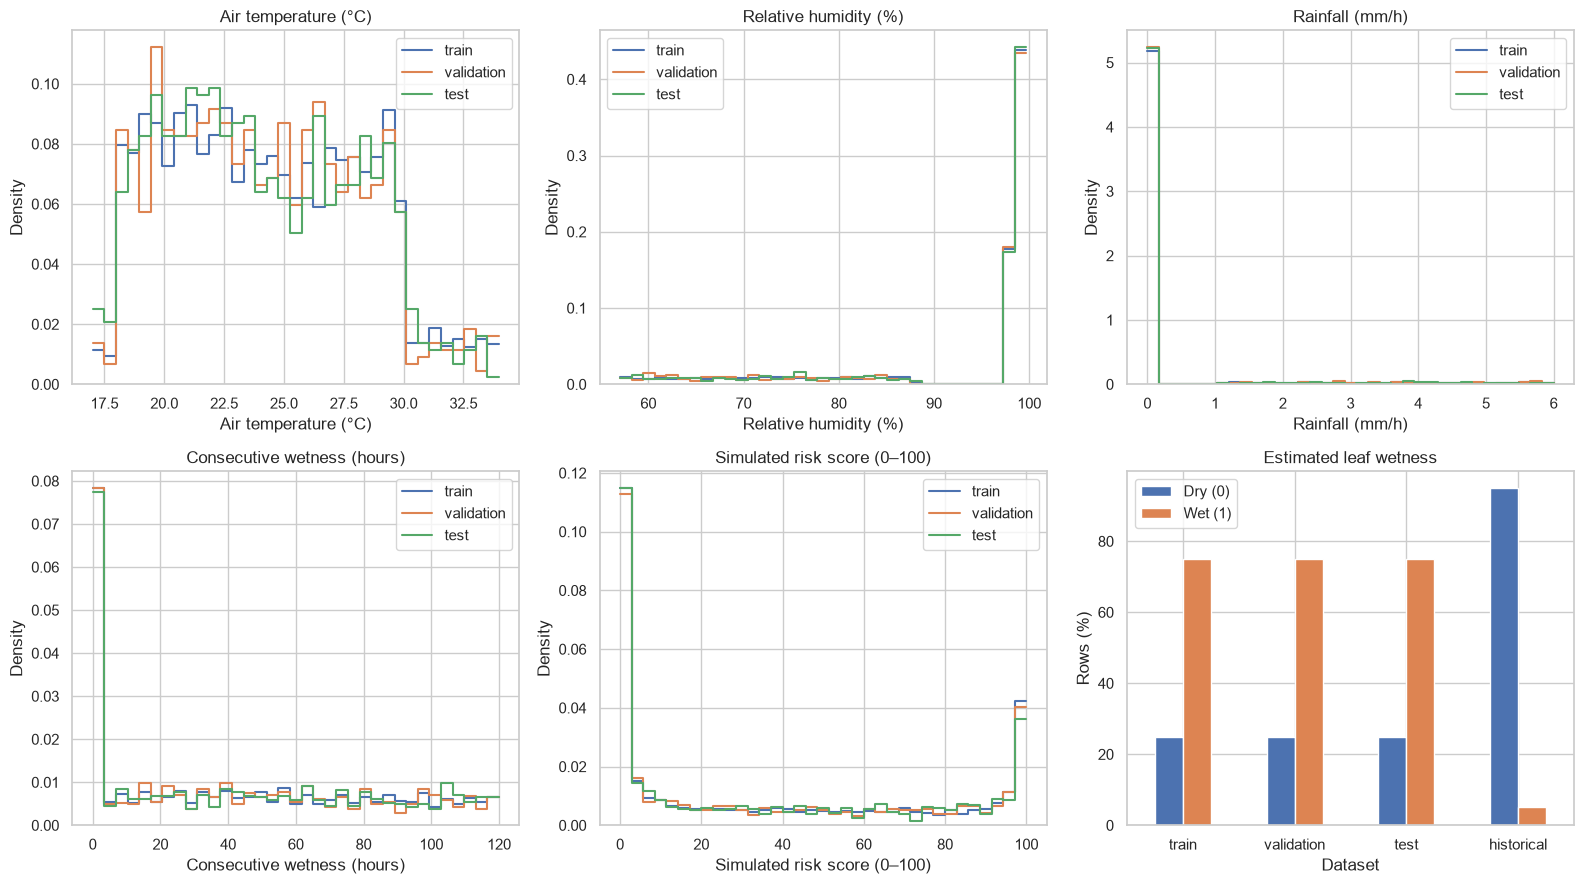

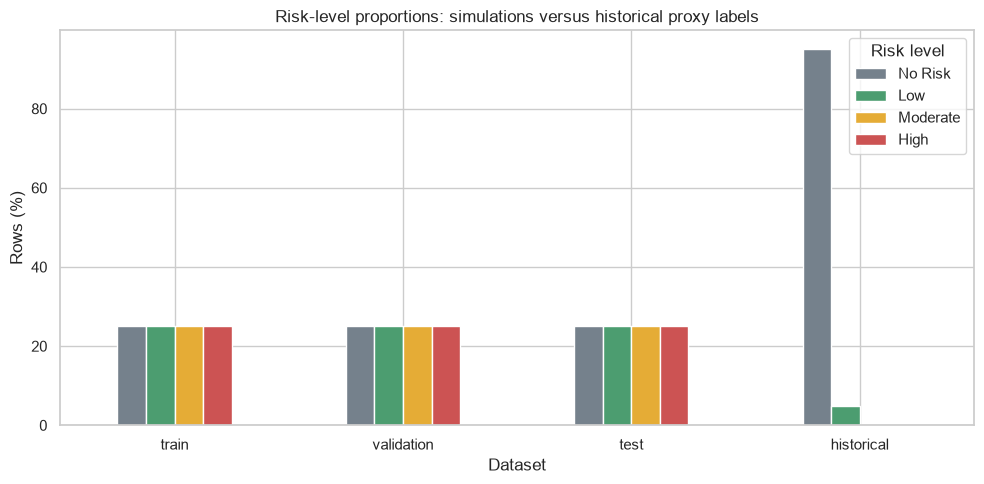

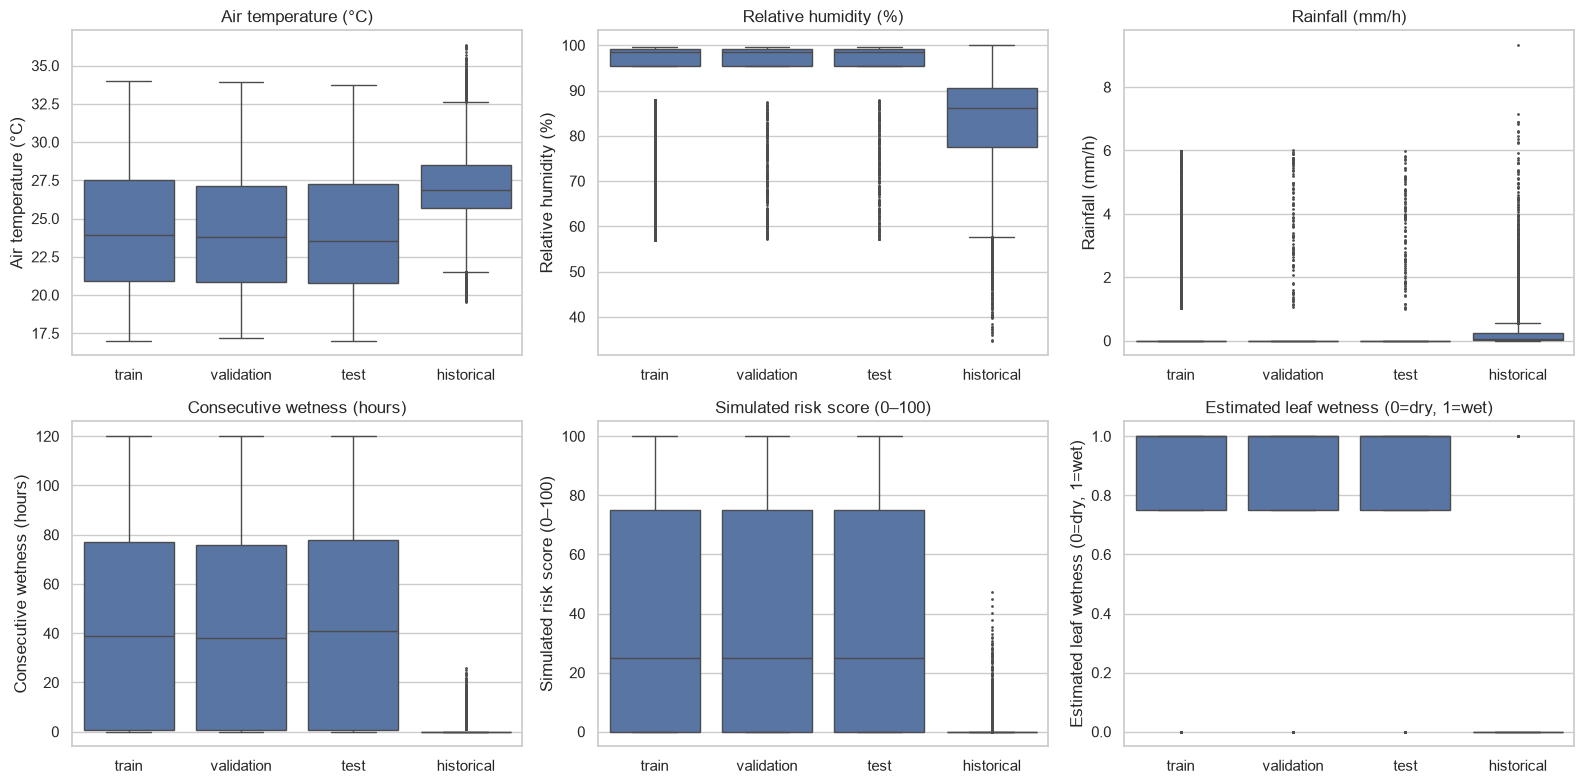

In [7]:
plot_features = ['air_temp_c','relative_humidity_pct','rainfall_mm_hr','consecutive_wetness_hours','risk_score']
fig, axes = plt.subplots(2,3,figsize=(16,9))
for ax,c in zip(axes.flat, plot_features):
    values = pd.concat([d[c] for s,d in datasets.items() if s != 'historical']).dropna()
    bins=np.linspace(values.min(), values.max(), 36)
    for s in ['train','validation','test']:
        sns.histplot(datasets[s][c], bins=bins, stat='density', element='step', fill=False, ax=ax, label=s)
    ax.set(xlabel=LABELS[c], ylabel='Density', title=LABELS[c]); ax.legend()
wet_pct = pd.DataFrame({s:d.estimated_leaf_wet.value_counts(normalize=True).reindex([0,1],fill_value=0)*100
                        for s,d in datasets.items()}).T
wet_pct.plot.bar(ax=axes.flat[5], rot=0)
axes.flat[5].set(title='Estimated leaf wetness',ylabel='Rows (%)',xlabel='Dataset')
axes.flat[5].legend(['Dry (0)','Wet (1)'])
savefig(fig,'environment_and_score_distributions')
fig, ax=plt.subplots(figsize=(10,5))
risk_pct.plot.bar(ax=ax,rot=0,color=['#75818c','#4c9d70','#e5ac36','#cc5353'])
ax.set(ylabel='Rows (%)',xlabel='Dataset',title='Risk-level proportions: simulations versus historical proxy labels')
ax.legend(title='Risk level'); savefig(fig,'risk_level_distributions')
fig, axes=plt.subplots(2,3,figsize=(16,8))
for ax,c in zip(axes.flat,plot_features + ['estimated_leaf_wet']):
    sns.boxplot(data=pd.concat([d[[c]].assign(dataset=s) for s,d in datasets.items()],ignore_index=True),
                x='dataset',y=c,ax=ax,fliersize=1)
    ax.set(xlabel='',ylabel=LABELS[c],title=LABELS[c])
savefig(fig,'distribution_boxplots')

## 6. Correlation analysis

Use training data to examine environmental correlations and feature-risk relationships. Pearson measures linear association; Spearman measures rank association. Neither establishes causation.

,air_temp_c,relative_humidity_pct,rainfall_mm_hr,dew_point_c,dew_point_depression_c,wind_speed_m_s,solar_radiation_mj_hr,estimated_leaf_wet,consecutive_wetness_hours,wet_hours_previous_24h,wet_hours_previous_72h
air_temp_c,1.000000,-0.159816,-0.041548,0.823525,0.181134,0.118729,0.511143,-0.179557,-0.140304,-0.160349,-0.155427
relative_humidity_pct,-0.159816,1.000000,0.172994,0.427277,-0.997860,0.047563,-0.483872,0.926843,0.606810,0.828250,0.675339
rainfall_mm_hr,-0.041548,0.172994,1.000000,0.059190,-0.169453,0.006776,-0.097346,0.186163,0.108825,0.167456,0.132758
dew_point_c,0.823525,0.427277,0.059190,1.000000,-0.408727,0.137495,0.186557,0.357157,0.212692,0.319260,0.237396
dew_point_depression_c,0.181134,-0.997860,-0.169453,-0.408727,1.000000,-0.047376,0.498913,-0.908065,-0.594472,-0.811472,-0.661631
wind_speed_m_s,0.118729,0.047563,0.006776,0.137495,-0.047376,1.000000,0.005164,0.054808,0.037749,0.043042,0.036852
solar_radiation_mj_hr,0.511143,-0.483872,-0.097346,0.186557,0.498913,0.005164,1.000000,-0.521679,-0.344181,-0.467529,-0.382914
estimated_leaf_wet,-0.179557,0.926843,0.186163,0.357157,-0.908065,0.054808,-0.521679,1.000000,0.653925,0.893535,0.727932
consecutive_wetness_hours,-0.140304,0.606810,0.108825,0.212692,-0.594472,0.037749,-0.344181,0.653925,1.000000,0.791606,0.963443
wet_hours_previous_24h,-0.160349,0.828250,0.167456,0.319260,-0.811472,0.043042,-0.467529,0.893535,0.791606,1.000000,0.874146


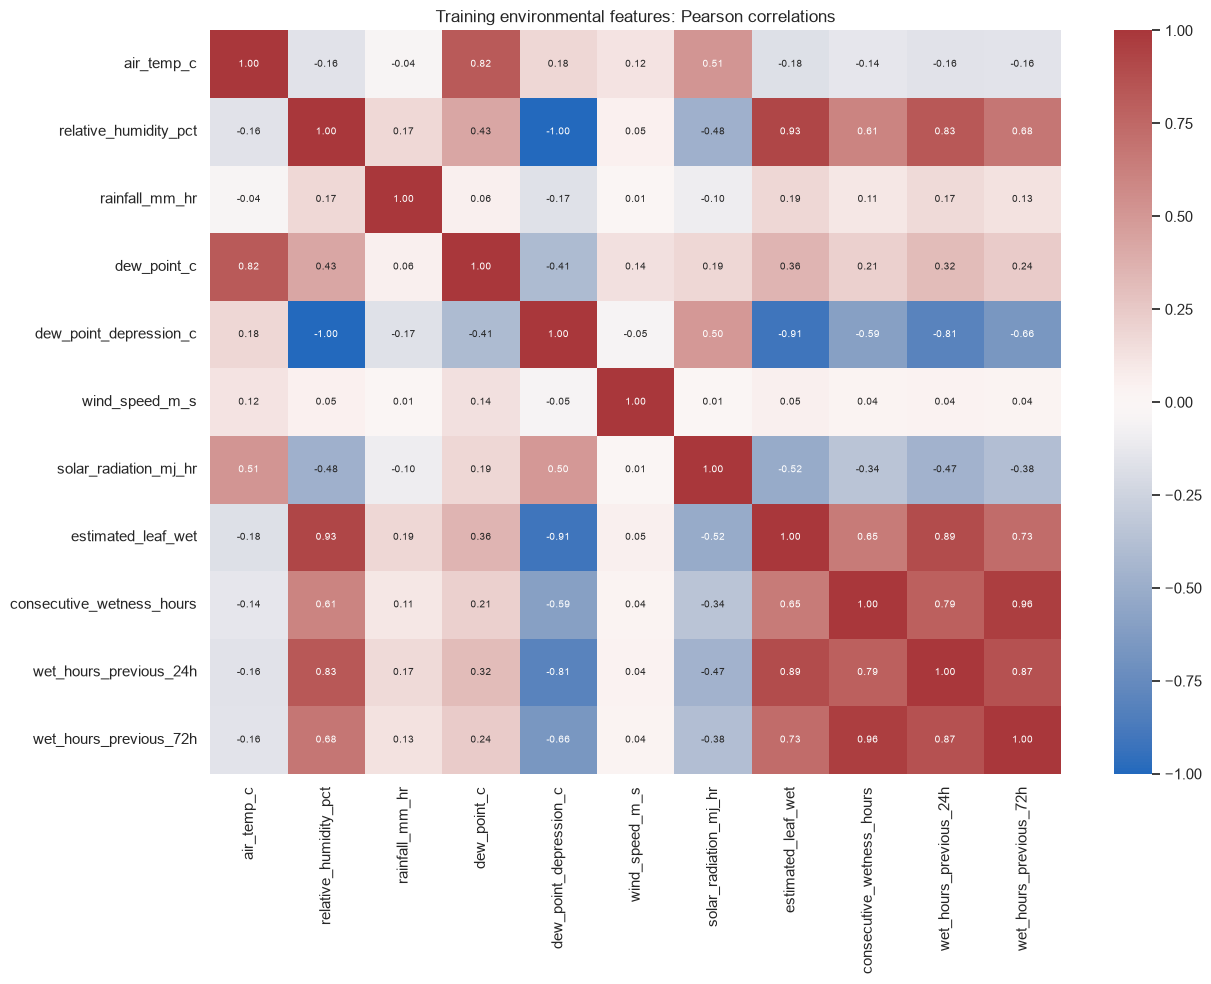

,pearson,spearman
air_temp_c,0.249594,0.191803
relative_humidity_pct,0.529493,0.570598
rainfall_mm_hr,0.089261,0.140062
dew_point_c,0.530376,0.527551
dew_point_depression_c,-0.517953,-0.556818
wind_speed_m_s,0.095851,0.090480
solar_radiation_mj_hr,-0.283273,-0.060079
estimated_leaf_wet,0.571073,0.755929
consecutive_wetness_hours,0.765941,0.856820
wet_hours_previous_24h,0.698917,0.841066


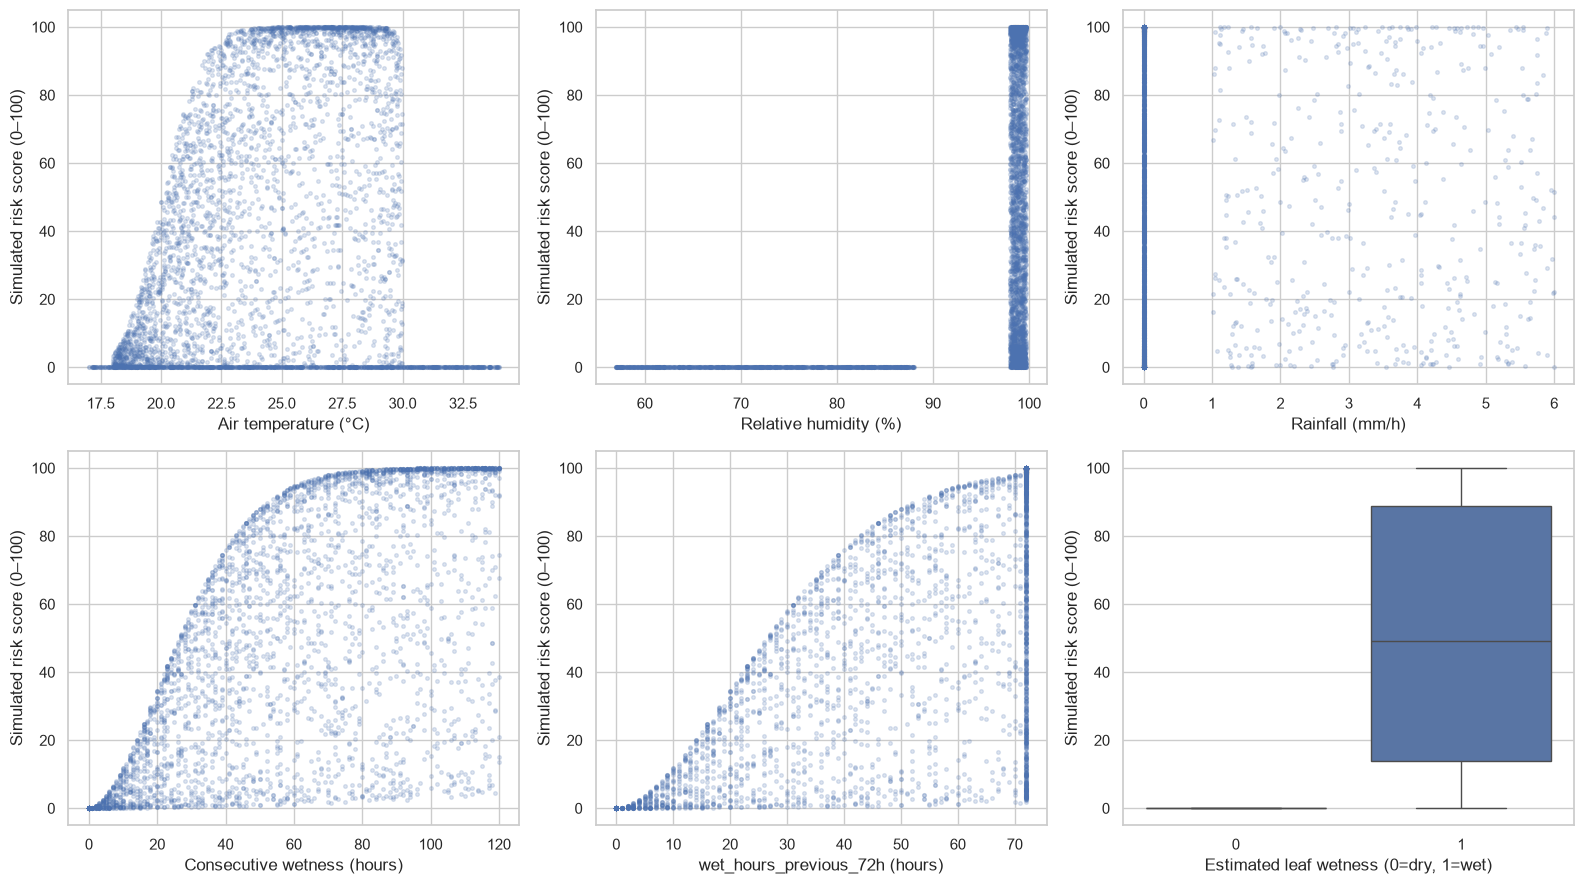

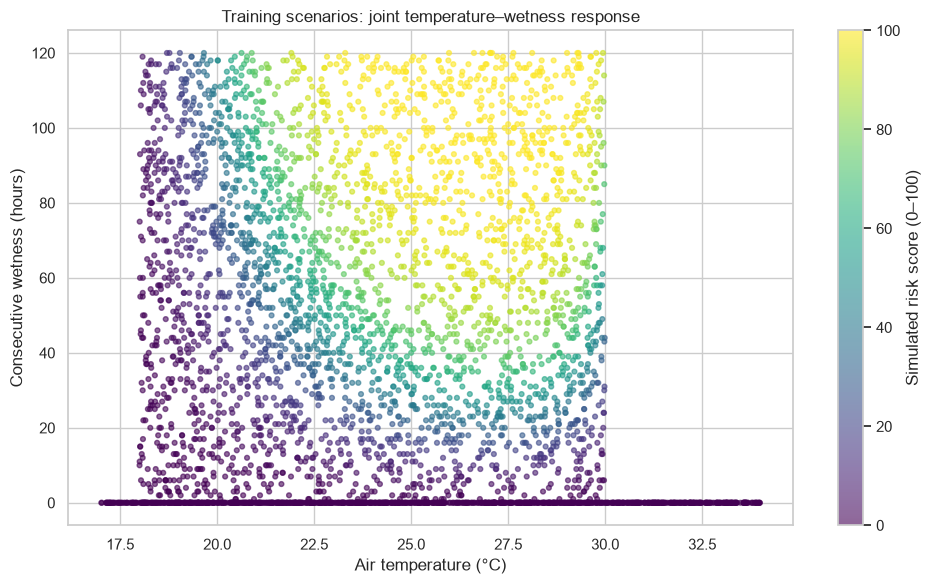

In [8]:
usable_env=[c for c in ENV if train[c].nunique(dropna=True)>1]
corr=train[usable_env].corr()
table(corr,'training_environment_pearson')
fig,ax=plt.subplots(figsize=(13,10))
sns.heatmap(corr,ax=ax,vmin=-1,vmax=1,center=0,cmap='vlag',annot=True,fmt='.2f',annot_kws={'size':7})
ax.set_title('Training environmental features: Pearson correlations')
savefig(fig,'environment_correlation_heatmap')
target_corr=pd.DataFrame({method:train[usable_env+['risk_score']].corr(method=method)['risk_score'].drop('risk_score')
                          for method in ['pearson','spearman']})
table(target_corr,'training_feature_risk_correlations')
fig,axes=plt.subplots(2,3,figsize=(16,9))
for ax,c in zip(axes.flat, ['air_temp_c','relative_humidity_pct','rainfall_mm_hr','consecutive_wetness_hours','wet_hours_previous_72h']):
    ax.scatter(train[c],train.risk_score,s=7,alpha=.18,rasterized=True)
    ax.set(xlabel=LABELS.get(c,c+' (hours)'),ylabel=LABELS['risk_score'])
sns.boxplot(data=train,x='estimated_leaf_wet',y='risk_score',ax=axes.flat[5],fliersize=1)
axes.flat[5].set(xlabel=LABELS['estimated_leaf_wet'],ylabel=LABELS['risk_score'])
savefig(fig,'features_versus_risk')
fig,ax=plt.subplots(figsize=(10,6))
points=ax.scatter(train.air_temp_c,train.consecutive_wetness_hours,c=train.risk_score,
                  cmap='viridis',vmin=0,vmax=100,s=12,alpha=.6)
ax.set(xlabel=LABELS['air_temp_c'],ylabel=LABELS['consecutive_wetness_hours'],title='Training scenarios: joint temperature–wetness response')
fig.colorbar(points,ax=ax,label=LABELS['risk_score'])
savefig(fig,'joint_temperature_wetness_risk')

## 7. Data leakage

Check shared IDs, records, inputs, and historical weather analogues across splits. Exclude target-derived `risk_level` and class-encoded scenario IDs from predictors.

Analogue proximity within 24, 72, or 120 hours indicates possible shared weather context, not confirmed shared windows. Counts represent left-side rows with any match. Matching inputs alone do not prove leakage.

In [9]:
def shared_rows(a,b,cols):
    # Exact column-wise equality using a pandas join (nulls match nulls).
    keys=b[cols].drop_duplicates()
    return int(a[cols].merge(keys.assign(_matched=True),on=cols,how='left')['_matched'].fillna(False).sum())
overlap=[]
for a,b in combinations(['train','validation','test'],2):
    left,right=datasets[a],datasets[b]
    row={'left':a,'right':b}
    for name,cols in [('full_row',list(train.columns)),('excluding_split',[c for c in train.columns if c!='split']),
                      ('scenario_id',['scenario_id']),('environment',ENV),('three_inputs',INPUTS),
                      ('three_inputs_and_score',INPUTS+['risk_score'])]:
        row[f'{name}_left_rows']=shared_rows(left,right,cols)
        row[f'{name}_right_rows']=shared_rows(right,left,cols)
    overlap.append(row)
overlap=pd.DataFrame(overlap)
table(overlap,'cross_split_exact_overlap')
times={s:pd.to_datetime(d.weather_analogue_timestamp_utc,utc=True,errors='coerce') for s,d in datasets.items() if s!='historical'}
time_audit=[]
def nearest_hours(left,right):
    a=left.dropna().astype('int64').to_numpy() # nanoseconds in the explicit ns conversion below
    b=np.sort(right.dropna().astype('int64').to_numpy())
    if not len(b): return np.full(len(a),np.inf)
    ix=np.searchsorted(b,a)
    low=b[np.clip(ix-1,0,len(b)-1)]; high=b[np.clip(ix,0,len(b)-1)]
    return np.minimum(np.abs(a-low),np.abs(a-high))/3.6e12
# Force nanosecond units; pandas may otherwise infer microseconds.
times={s:t.astype('datetime64[ns, UTC]') for s,t in times.items()}
for a,b in combinations(times,2):
    delta=nearest_hours(times[a],times[b])
    time_audit.append({'left':a,'right':b,'left_rows':len(delta),
                       'exact_shared_analogue_left_rows':int((delta==0).sum()),
                       **{f'left_rows_within_{h}h':int((delta<h).sum()) for h in [24,72,120]}})
time_audit=pd.DataFrame(time_audit)
table(time_audit,'analogue_window_overlap')
hist_time=pd.to_datetime(historical.timestamp_utc,utc=True,errors='coerce').astype('datetime64[ns, UTC]')
hist_lookup=pd.Series(historical['split'].to_numpy(),index=hist_time)
analogue_rows=[]
for s,t in times.items():
    source_split=t.map(hist_lookup)
    analogue_rows.append({'dataset':s,'missing_or_invalid_analogue_times':int(t.isna().sum()),
                         'unique_analogues':t.nunique(),'analogues_matching_historical_rows':int(source_split.notna().sum()),
                         'historical_split_differs_from_simulated':int((source_split.notna() & source_split.ne(s)).sum())})
analogue_audit=pd.DataFrame(analogue_rows).set_index('dataset')
table(analogue_audit,'analogue_provenance_audit')
id_labels=train.scenario_id.str.extract(r'^SIM_(NORISK|LOW|MODERATE|HIGH)_',expand=False).map(
    {'NORISK':'No Risk','LOW':'Low','MODERATE':'Moderate','HIGH':'High'})
print('Training scenario IDs decoding to their risk level:',int(id_labels.eq(train.risk_level).sum()),'of',len(train))
print('Wet-window identities in simulated training (redundancy, not independent measurements):')
for c,h in [('wet_hours_previous_24h',24),('wet_hours_previous_72h',72)]:
    print(c,'equals clipped consecutive wetness:',int(train[c].eq(train.consecutive_wetness_hours.clip(upper=h)).sum()),'/',len(train))

,left,right,full_row_left_rows,full_row_right_rows,excluding_split_left_rows,excluding_split_right_rows,scenario_id_left_rows,scenario_id_right_rows,environment_left_rows,environment_right_rows,three_inputs_left_rows,three_inputs_right_rows,three_inputs_and_score_left_rows,three_inputs_and_score_right_rows
0,train,validation,0,0,0,0,0,0,0,0,10,9,10,9
1,train,test,0,0,0,0,0,0,0,0,13,12,12,11
2,validation,test,0,0,0,0,0,0,0,0,2,2,1,1


,left,right,left_rows,exact_shared_analogue_left_rows,left_rows_within_24h,left_rows_within_72h,left_rows_within_120h
0,train,validation,4200,1134,3330,4082,4174
1,train,test,4200,1108,3276,4059,4158
2,validation,test,900,243,707,871,892


,missing_or_invalid_analogue_times,unique_analogues,analogues_matching_historical_rows,historical_split_differs_from_simulated
dataset,,,,
train,0,2834,4200,1061
validation,0,728,900,762
test,0,720,900,832


Training scenario IDs decoding to their risk level: 4200 of 4200
Wet-window identities in simulated training (redundancy, not independent measurements):
wet_hours_previous_24h equals clipped consecutive wetness: 4200 / 4200
wet_hours_previous_72h equals clipped consecutive wetness: 4200 / 4200


### Historical time windows

Check hourly continuity, split boundaries, warmup rows, and whether rolling summaries include the current hour.

In [10]:
historical_time_summary=pd.DataFrame([{'rows':len(historical),'invalid_timestamps':int(hist_time.isna().sum()),
    'duplicate_timestamps_after_first':int(hist_time.duplicated().sum()),'start_utc':hist_time.min(),'end_utc':hist_time.max(),
    'non_hourly_steps_in_file_order':int(hist_time.diff().dropna().ne(pd.Timedelta(hours=1)).sum())}])
table(historical_time_summary,'historical_time_summary')
segments=historical['split'].ne(historical['split'].shift()).cumsum()
blocks=historical.assign(parsed_time=hist_time,block=segments).groupby('block').agg(
    split=('split','first'),start=('parsed_time','min'),end=('parsed_time','max'),rows=('split','size'))
table(blocks,'historical_split_blocks')
rolling_audit=[]
for dest,src,h,agg in [('wet_hours_previous_24h','estimated_leaf_wet',24,'sum'),
                       ('wet_hours_previous_72h','estimated_leaf_wet',72,'sum'),
                       ('rain_previous_24h_mm','rainfall_mm_hr',24,'sum'),
                       ('mean_temp_previous_24h_c','air_temp_c',24,'mean'),
                       ('mean_rh_previous_24h_pct','relative_humidity_pct',24,'mean')]:
    for shift in [0,1]:
        calculated=getattr(historical[src].shift(shift).rolling(h,min_periods=h),agg)()
        valid=historical[dest].notna() & calculated.notna()
        rolling_audit.append({'feature':dest,'excluded_current_hour':bool(shift),'comparable_rows':int(valid.sum()),
                              'mismatches_tolerance_1e-5':int((~np.isclose(historical.loc[valid,dest],calculated[valid],atol=1e-5,rtol=0)).sum())})
rolling_audit=pd.DataFrame(rolling_audit)
table(rolling_audit,'historical_rolling_consistency')
historical_windows=[]
for h in [24,72]:
    earlier=historical['split'].shift(h-1)
    # Boundaries are contiguous blocks; crossing a block flags potentially shared context.
    crosses=segments.ne(segments.shift(h-1)) & segments.shift(h-1).notna()
    for s in ['train','validation','test']:
        historical_windows.append({'split':s,'window_hours':h,
                                    'rows_with_context_crossing_block':int((crosses & historical['split'].eq(s)).sum())})
table(pd.DataFrame(historical_windows),'historical_window_boundary_audit')

,rows,invalid_timestamps,duplicate_timestamps_after_first,start_utc,end_utc,non_hourly_steps_in_file_order
0,26304,0,0,2022-01-01 00:00:00+00:00,2024-12-31 23:00:00+00:00,0


,split,start,end,rows
block,,,,
1,excluded_warmup,2022-01-01 00:00:00+00:00,2022-01-03 23:00:00+00:00,72
2,train,2022-01-04 00:00:00+00:00,2023-12-31 23:00:00+00:00,17448
3,excluded_warmup,2024-01-01 00:00:00+00:00,2024-01-03 23:00:00+00:00,72
4,validation,2024-01-04 00:00:00+00:00,2024-06-30 23:00:00+00:00,4296
5,excluded_warmup,2024-07-01 00:00:00+00:00,2024-07-03 23:00:00+00:00,72
6,test,2024-07-04 00:00:00+00:00,2024-12-31 23:00:00+00:00,4344


,feature,excluded_current_hour,comparable_rows,mismatches_tolerance_1e-5
0,wet_hours_previous_24h,False,26281,0
1,wet_hours_previous_24h,True,26280,2244
2,wet_hours_previous_72h,False,26233,0
3,wet_hours_previous_72h,True,26232,2358
4,rain_previous_24h_mm,False,26281,0
5,rain_previous_24h_mm,True,26280,21788
6,mean_temp_previous_24h_c,False,26281,0
7,mean_temp_previous_24h_c,True,26280,26046
8,mean_rh_previous_24h_pct,False,26281,0
9,mean_rh_previous_24h_pct,True,26280,26247


,split,window_hours,rows_with_context_crossing_block
0,train,24,23
1,validation,24,23
2,test,24,23
3,train,72,71
4,validation,72,71
5,test,72,71


## 8. Historical comparison

Compare training and historical ranges, averages, and cumulative distributions. ECDF separation indicates distribution shift. Historical weather is a reference, not an independent disease validation set.

,train_n,historical_n,train_mean,historical_mean,train_median,historical_median,train_min,train_max,historical_min,historical_max,train_outside_historical_range_percent
feature,,,,,,,,,,,
air_temp_c,4200,26304,24.246660,27.022467,23.94100,26.86000,17.015,33.988,19.560000,36.330000,14.119048
relative_humidity_pct,4200,26304,92.347731,83.269117,98.56000,86.21000,57.020,99.700,34.740000,100.000000,0.000000
rainfall_mm_hr,4200,26304,0.377005,0.221954,0.00000,0.06000,0.000,5.990,0.000000,9.320000,0.000000
dew_point_c,4200,26304,22.766971,23.828806,22.72000,24.01000,9.200,31.570,15.900000,26.840000,26.976190
dew_point_depression_c,4200,26304,1.479676,3.193663,0.24000,2.47000,0.040,9.650,0.000000,17.700000,0.000000
wind_speed_m_s,4200,26304,3.592690,3.853959,3.64000,3.95000,0.050,9.530,0.010000,10.070000,0.000000
solar_radiation_mj_hr,4200,26304,0.260546,0.831992,0.00000,0.03000,0.000,3.690,0.000000,3.700000,0.000000
estimated_leaf_wet,4200,26304,0.750000,0.050905,1.00000,0.00000,0.000,1.000,0.000000,1.000000,0.000000
consecutive_wetness_hours,4200,26304,44.105714,0.256843,39.00000,0.00000,0.000,120.000,0.000000,26.000000,58.309524


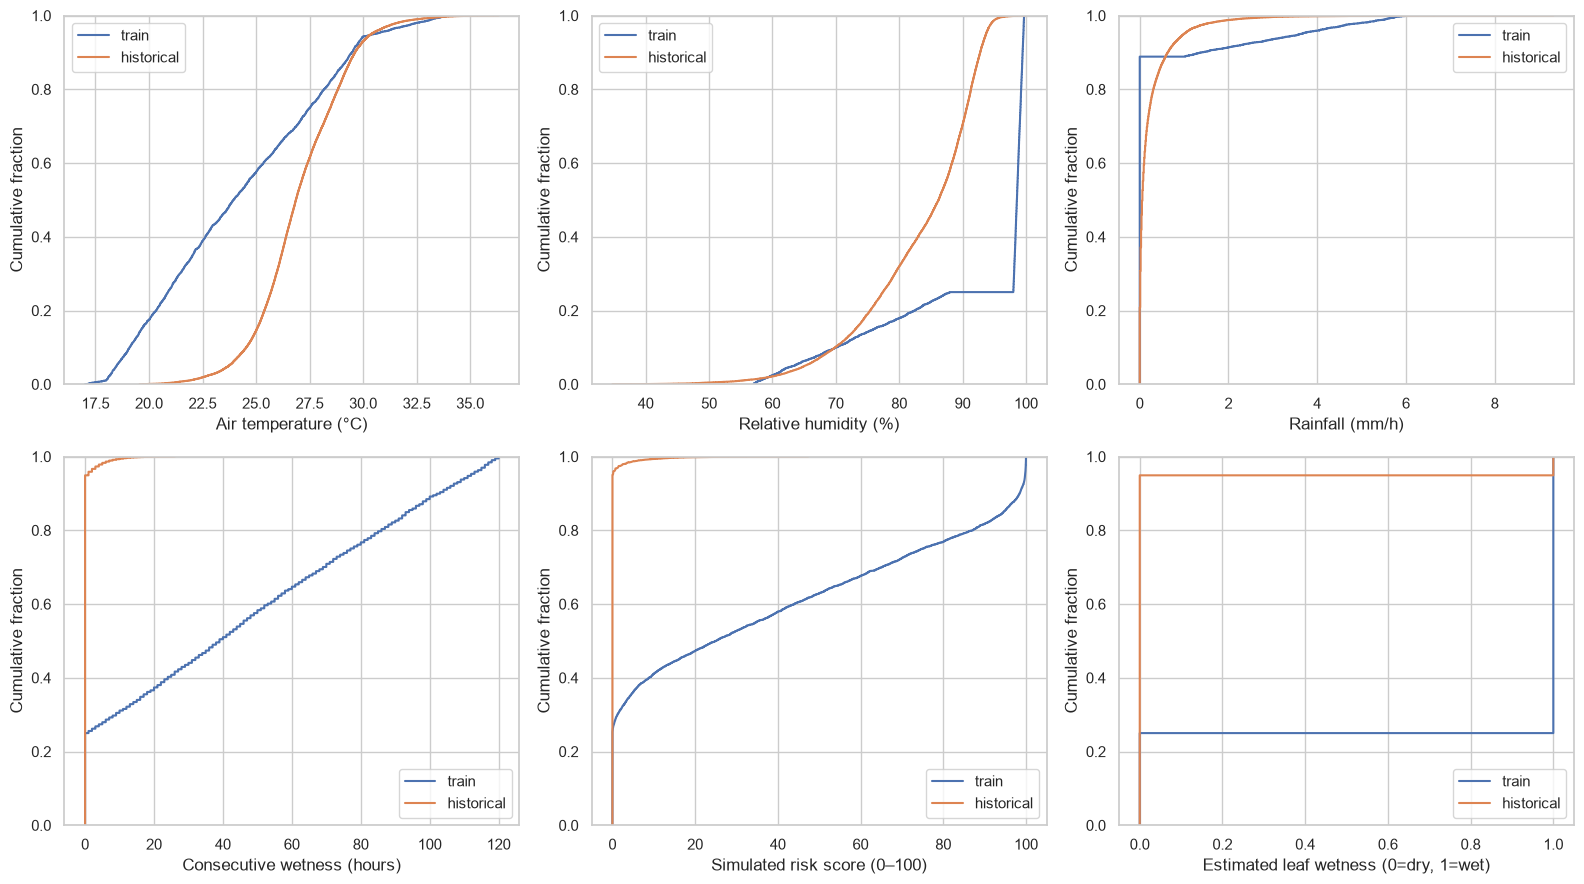

In [11]:
comparison=[]
for c in ENV+['risk_score']:
    a=train[c].dropna(); b=historical[c].dropna()
    comparison.append({'feature':c,'train_n':len(a),'historical_n':len(b),
        'train_mean':a.mean(),'historical_mean':b.mean(),'train_median':a.median(),'historical_median':b.median(),
        'train_min':a.min(),'train_max':a.max(),'historical_min':b.min(),'historical_max':b.max(),
        'train_outside_historical_range_percent':100*((a<b.min()) | (a>b.max())).mean() if len(a) and len(b) else np.nan})
comparison=pd.DataFrame(comparison).set_index('feature')
table(comparison,'training_historical_comparison')
fig,axes=plt.subplots(2,3,figsize=(16,9))
for ax,c in zip(axes.flat,plot_features+['estimated_leaf_wet']):
    for s in ['train','historical']:
        sns.ecdfplot(data=datasets[s],x=c,ax=ax,label=s)
    ax.set(xlabel=LABELS[c],ylabel='Cumulative fraction'); ax.legend()
savefig(fig,'training_historical_ecdfs')

## 9. Preliminary feature assessment

Assess `air_temp_c`, `estimated_leaf_wet`, and `consecutive_wetness_hours` against `risk_score`. Check coverage, missingness, redundancy, correlations, and conflicting scores for repeated inputs.

In [12]:
feature_assessment=pd.DataFrame({c:{'missing_train':int(train[c].isna().sum()),'unique_train':train[c].nunique(),
                                    'train_min':train[c].min(),'train_max':train[c].max(),
                                    'historical_min':historical[c].min(),'historical_max':historical[c].max(),
                                    'pearson_with_risk':train[c].corr(train.risk_score),
                                    'spearman_with_risk':train[c].corr(train.risk_score,method='spearman')}
                                for c in INPUTS}).T
table(feature_assessment,'preliminary_feature_assessment')
all_sim=pd.concat([datasets[s].assign(file_split=s) for s in ['train','validation','test']],ignore_index=True)
conflicts=all_sim.groupby(INPUTS,dropna=False).risk_score.agg(['size','nunique','min','max'])
conflicts=conflicts.loc[conflicts['nunique'].gt(1)]
table(conflicts,'three_input_conflicting_scores')
wet_equivalence={s:int(d.estimated_leaf_wet.ne(d.consecutive_wetness_hours.gt(0).astype(int)).sum()) for s,d in datasets.items()}
print('Wet flag versus (consecutive wetness > 0) mismatches:',wet_equivalence)

,missing_train,unique_train,train_min,train_max,historical_min,historical_max,pearson_with_risk,spearman_with_risk
air_temp_c,0.0,3609.0,17.015,33.988,19.56,36.33,0.249594,0.191803
estimated_leaf_wet,0.0,2.0,0.000,1.000,0.00,1.00,0.571073,0.755929
consecutive_wetness_hours,0.0,121.0,0.000,120.000,0.00,26.00,0.765941,0.856820


,,,size,nunique,min,max
air_temp_c,estimated_leaf_wet,consecutive_wetness_hours,,,,
20.624,1,108,2,2,60.8005,60.8106
22.185,1,20,2,2,11.6491,11.6515
22.604,1,11,2,2,5.1169,5.1175
23.297,1,37,2,2,44.4125,44.4167
28.929,1,47,2,2,75.6192,75.6225
28.962,1,65,2,2,91.4572,91.4577


Wet flag versus (consecutive wetness > 0) mismatches: {'train': 0, 'validation': 0, 'test': 0, 'historical': 0}


## 10. Conclusions

Summarize findings, limitations, and next steps. Save `EDA_Report.md` and verify source CSV checksums. Accuracy on simulated labels cannot establish real disease prediction accuracy.

In [13]:
def md_table(df):
    # Avoid an optional tabulate dependency.
    x=df.reset_index().astype(str)
    return '| '+' | '.join(map(str,x.columns))+' |\n| '+' | '.join(['---']*len(x.columns))+' |\n'+'\n'.join('| '+' | '.join(row)+' |' for row in x.to_numpy())
nonzero_quality=quality.loc[quality.flagged_rows.gt(0)]
lines=[
    '# Black Sigatoka EDA Report',
    'Scope: Cavendish banana environmental risk research, Bingiriya, Sri Lanka. All results below are computed from the supplied CSVs. Labels are research-informed mathematical proxies, not confirmed disease observations.',
    '## Dataset overview',md_table(overview),
    'All four files have the same column names. CSV-inferred types differ where columns are entirely empty. No README, scoring generator, or threshold specification was available in the inspected project.',
    '## Risk distribution',md_table(risk_counts),
    f'Training score range: {train.risk_score.min():.4f}–{train.risk_score.max():.4f}; historical score range: {historical.risk_score.min():.4f}–{historical.risk_score.max():.4f}. Simulated splits each allocate 25% to every level. This class balance is constructed and is not an estimate of disease prevalence.',
    'Hypothesized bins: zero = No Risk, (0,25) = Low, [25,75) = Moderate, [75,100] = High. These are inferred, not documented or independently verified. Boundary conventions, near-zero tolerance, and the continuous label formula remain unresolved.',
    md_table(risk_audit),
    '## Data quality',
    'Missing values are retained. Missingness includes structural unavailable fields and historical rolling warmup. See missing_values.csv for all columns and percentages.',
    md_table(missing.loc[missing['missing'].gt(0)]),
    'Nonzero validity/consistency flags (empty table means none under the explicit checks):',md_table(nonzero_quality),
    'Historical dew-point inconsistency examples:',md_table(dew_examples),
    md_table(duplicates),
    'IQR screening is saved in iqr_outlier_screen.csv; flags do not establish bad observations. Zero-inflated rainfall and wetness can produce narrow or zero IQRs. No rows or values were altered.',
    '## Leakage and split independence',
    'risk_level is target-derived. scenario_id encodes the risk class and must not be a predictor. Keep risk_score only as the target. Exclude provenance, split, and identifier fields from predictors. Temperature/wetness associations with risk reflect the synthetic scoring mechanism, not evidence of biological predictive validity.',
    md_table(overlap),md_table(time_audit),md_table(analogue_audit),
    f"No shared scenario IDs or exact complete environmental records were found between simulated splits. However, {time_audit.iloc[0]['exact_shared_analogue_left_rows']} training rows reuse validation analogue timestamps and {time_audit.iloc[1]['exact_shared_analogue_left_rows']} reuse test analogue timestamps. These observations are not additive because a training row may match both splits.",
    'Exact overlap counts are directional row counts. Feature matches need not be duplicate observations. Analogue proximity uses strict distances <24, <72, and <120 hours and indicates possible shared context; it does not prove actual shared scenario windows. Random scenario splits cannot be assumed independent of historical source weather. Source generation and grouping must be recovered before deciding how to evaluate.',
    'Historical chronology and boundaries:',md_table(historical_time_summary),md_table(blocks),
    'Rolling checks compare both inclusive-current and previous-only window interpretations:',md_table(rolling_audit),
    'All five historical rolling-summary checks match the inclusive-current-hour interpretation on comparable rows. The names previous_24h/previous_72h therefore do not establish a strictly previous-only window. Historical split blocks include 72 excluded warmup hours at each partition start; do not discard these protections in a future design.',
    '## Historical distribution comparison',
    md_table(comparison.loc[INPUTS+['relative_humidity_pct','rainfall_mm_hr','risk_score']]),
    f"Wet-row fraction: training {train.estimated_leaf_wet.mean()*100:.2f}%, historical {historical.estimated_leaf_wet.mean()*100:.2f}%. Historical No Risk: {risk_pct.loc['historical','No Risk']:.2f}%; historical High rows: {risk_counts.loc['historical','High']}.",
    'Balanced synthetic scenarios cover different temperature/wetness conditions from the historical baseline. The historical data are gridded weather with estimated, uncalibrated wetness; air temperature is a canopy-temperature proxy. They are not field disease observations or an independent disease test set.',
    '## Preliminary feature assessment',md_table(feature_assessment),
    f'Wet flag versus positive consecutive wetness mismatches by file: {wet_equivalence}. Repeated three-input combinations with more than one score across simulated files: {len(conflicts)} groups.',
    'Associations and the joint temperature–wetness figure support examining a nonlinear response. Marginal correlations cannot rank causal importance. Clipped wet-window features may be redundant with consecutive duration. No model was trained and no features were selected automatically.',
    '## Recommendations for the next stage',
    '1. Recover the generator, exact score formula, thresholds, rounding policy, and scientific references. Confirm proxy wetness and rolling-window conventions; resolve flagged inconsistencies before changing data.',
    '2. Define whether the task estimates contemporaneous proxy risk or forecasts a future horizon. Confirm all candidate inputs are available at that prediction time.',
    '3. Plan source-aware grouped/temporal validation using analogue identities and weather blocks, with a gap appropriate to every feature window (audit includes up to 120-hour scenario spells). Audit again after any future split redesign; do not mix simulated rows and their source history as independent evaluation records.',
    '4. Review structural missingness, all-empty variables, redundant wetness features, and outlier context. Any future imputation or learned transformation must be fitted on training data only. No such processing was done in this EDA.',
    '5. Obtain local measured leaf wetness, canopy conditions, and confirmed disease outcomes for biological calibration and external validation. High accuracy against synthetic labels would demonstrate reproduction of the scoring function, not real disease prediction accuracy.',
    '## Artifacts and verification',
    'The notebook contains all code, explanations, outputs, and figures. Detailed numerical tables are saved as CSV alongside this report. Figures:',
    *[f'- [{f}]({f})' for f in figures],
    'Source SHA-256 checksums are saved in source_manifest.json and checked on every complete EDA run. EDA imports are consolidated and Markdown is shortened; all EDA calculations are retained. No cleaning, preprocessing, or model training was performed.',
    'Unverified: documented label thresholds/formula; field disease validity; NASA extraction provenance/location; actual shared generator weather windows. CSV metadata alone cannot establish these.'
]
assert all(hashlib.sha256(p.read_bytes()).hexdigest()==source_hashes[s] for s,p in FILES.items()), 'Source CSV changed during EDA'
(OUT/'source_manifest.json').write_text(json.dumps({s:{'filename':FILES[s].name,'sha256':h} for s,h in source_hashes.items()},indent=2),encoding='utf-8')
report='\n\n'.join(lines)+'\n'
(OUT/'EDA_Report.md').write_text(report,encoding='utf-8')
display(Markdown(report))
print('Verified: all four source CSV checksums unchanged. EDA complete; no preprocessing or training performed.')

# Black Sigatoka EDA Report

Scope: Cavendish banana environmental risk research, Bingiriya, Sri Lanka. All results below are computed from the supplied CSVs. Labels are research-informed mathematical proxies, not confirmed disease observations.

## Dataset overview

| index | rows | columns |
| --- | --- | --- |
| train | 4200 | 25 |
| validation | 900 | 25 |
| test | 900 | 25 |
| historical | 26304 | 25 |

All four files have the same column names. CSV-inferred types differ where columns are entirely empty. No README, scoring generator, or threshold specification was available in the inspected project.

## Risk distribution

| index | No Risk | Low | Moderate | High |
| --- | --- | --- | --- | --- |
| train | 1050 | 1050 | 1050 | 1050 |
| validation | 225 | 225 | 225 | 225 |
| test | 225 | 225 | 225 | 225 |
| historical | 24990 | 1288 | 26 | 0 |

Training score range: 0.0000–99.9950; historical score range: 0.0000–47.2873. Simulated splits each allocate 25% to every level. This class balance is constructed and is not an estimate of disease prevalence.

Hypothesized bins: zero = No Risk, (0,25) = Low, [25,75) = Moderate, [75,100] = High. These are inferred, not documented or independently verified. Boundary conventions, near-zero tolerance, and the continuous label formula remain unresolved.

| dataset | missing_score | outside_0_100 | unknown_or_missing_level | hypothesized_rule_mismatches | exact_score_0 | exact_score_25 | exact_score_75 | exact_score_100 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| train | 0 | 0 | 0 | 0 | 1050 | 0 | 0 | 0 |
| validation | 0 | 0 | 0 | 0 | 225 | 0 | 0 | 0 |
| test | 0 | 0 | 0 | 0 | 225 | 0 | 0 | 0 |
| historical | 0 | 0 | 0 | 0 | 24990 | 0 | 0 | 0 |

## Data quality

Missing values are retained. Missingness includes structural unavailable fields and historical rolling warmup. See missing_values.csv for all columns and percentages.

| dataset | column | missing | percent |
| --- | --- | --- | --- |
| train | timestamp_utc | 4200 | 100.0 |
| train | rain_previous_24h_mm | 4200 | 100.0 |
| train | mean_temp_previous_24h_c | 4200 | 100.0 |
| train | mean_rh_previous_24h_pct | 4200 | 100.0 |
| train | canopy_temperature_c | 4200 | 100.0 |
| validation | timestamp_utc | 900 | 100.0 |
| validation | rain_previous_24h_mm | 900 | 100.0 |
| validation | mean_temp_previous_24h_c | 900 | 100.0 |
| validation | mean_rh_previous_24h_pct | 900 | 100.0 |
| validation | canopy_temperature_c | 900 | 100.0 |
| test | timestamp_utc | 900 | 100.0 |
| test | rain_previous_24h_mm | 900 | 100.0 |
| test | mean_temp_previous_24h_c | 900 | 100.0 |
| test | mean_rh_previous_24h_pct | 900 | 100.0 |
| test | canopy_temperature_c | 900 | 100.0 |
| historical | wet_hours_previous_24h | 23 | 0.08743917274939172 |
| historical | wet_hours_previous_72h | 71 | 0.26992092457420924 |
| historical | rain_previous_24h_mm | 23 | 0.08743917274939172 |
| historical | mean_temp_previous_24h_c | 23 | 0.08743917274939172 |
| historical | mean_rh_previous_24h_pct | 23 | 0.08743917274939172 |
| historical | canopy_temperature_c | 26304 | 100.0 |
| historical | weather_analogue_timestamp_utc | 26304 | 100.0 |

Nonzero validity/consistency flags (empty table means none under the explicit checks):

| index | dataset | check | flagged_rows |
| --- | --- | --- | --- |
| 159 | historical | dew point above air + 0.02°C | 1 |
| 160 | historical | dew depression discrepancy > 0.02°C | 1 |

Historical dew-point inconsistency examples:

| index | scenario_id | timestamp_utc | air_temp_c | dew_point_c | dew_point_depression_c |
| --- | --- | --- | --- | --- | --- |
| 18119 | NASA_18119 | 2024-01-25 23:00:00+00:00 | 20.37 | 20.41 | 0.0 |

| dataset | full_row_duplicates_after_first | duplicate_scenario_ids_after_first | environment_duplicates_after_first | three_input_duplicates_after_first |
| --- | --- | --- | --- | --- |
| train | 0 | 0 | 0 | 36 |
| validation | 0 | 0 | 0 | 3 |
| test | 0 | 0 | 0 | 4 |
| historical | 0 | 0 | 0 | 23773 |

IQR screening is saved in iqr_outlier_screen.csv; flags do not establish bad observations. Zero-inflated rainfall and wetness can produce narrow or zero IQRs. No rows or values were altered.

## Leakage and split independence

risk_level is target-derived. scenario_id encodes the risk class and must not be a predictor. Keep risk_score only as the target. Exclude provenance, split, and identifier fields from predictors. Temperature/wetness associations with risk reflect the synthetic scoring mechanism, not evidence of biological predictive validity.

| index | left | right | full_row_left_rows | full_row_right_rows | excluding_split_left_rows | excluding_split_right_rows | scenario_id_left_rows | scenario_id_right_rows | environment_left_rows | environment_right_rows | three_inputs_left_rows | three_inputs_right_rows | three_inputs_and_score_left_rows | three_inputs_and_score_right_rows |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | train | validation | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 10 | 9 | 10 | 9 |
| 1 | train | test | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 13 | 12 | 12 | 11 |
| 2 | validation | test | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 2 | 2 | 1 | 1 |

| index | left | right | left_rows | exact_shared_analogue_left_rows | left_rows_within_24h | left_rows_within_72h | left_rows_within_120h |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | train | validation | 4200 | 1134 | 3330 | 4082 | 4174 |
| 1 | train | test | 4200 | 1108 | 3276 | 4059 | 4158 |
| 2 | validation | test | 900 | 243 | 707 | 871 | 892 |

| dataset | missing_or_invalid_analogue_times | unique_analogues | analogues_matching_historical_rows | historical_split_differs_from_simulated |
| --- | --- | --- | --- | --- |
| train | 0 | 2834 | 4200 | 1061 |
| validation | 0 | 728 | 900 | 762 |
| test | 0 | 720 | 900 | 832 |

No shared scenario IDs or exact complete environmental records were found between simulated splits. However, 1134 training rows reuse validation analogue timestamps and 1108 reuse test analogue timestamps. These observations are not additive because a training row may match both splits.

Exact overlap counts are directional row counts. Feature matches need not be duplicate observations. Analogue proximity uses strict distances <24, <72, and <120 hours and indicates possible shared context; it does not prove actual shared scenario windows. Random scenario splits cannot be assumed independent of historical source weather. Source generation and grouping must be recovered before deciding how to evaluate.

Historical chronology and boundaries:

| index | rows | invalid_timestamps | duplicate_timestamps_after_first | start_utc | end_utc | non_hourly_steps_in_file_order |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | 26304 | 0 | 0 | 2022-01-01 00:00:00+00:00 | 2024-12-31 23:00:00+00:00 | 0 |

| block | split | start | end | rows |
| --- | --- | --- | --- | --- |
| 1 | excluded_warmup | 2022-01-01 00:00:00+00:00 | 2022-01-03 23:00:00+00:00 | 72 |
| 2 | train | 2022-01-04 00:00:00+00:00 | 2023-12-31 23:00:00+00:00 | 17448 |
| 3 | excluded_warmup | 2024-01-01 00:00:00+00:00 | 2024-01-03 23:00:00+00:00 | 72 |
| 4 | validation | 2024-01-04 00:00:00+00:00 | 2024-06-30 23:00:00+00:00 | 4296 |
| 5 | excluded_warmup | 2024-07-01 00:00:00+00:00 | 2024-07-03 23:00:00+00:00 | 72 |
| 6 | test | 2024-07-04 00:00:00+00:00 | 2024-12-31 23:00:00+00:00 | 4344 |

Rolling checks compare both inclusive-current and previous-only window interpretations:

| index | feature | excluded_current_hour | comparable_rows | mismatches_tolerance_1e-5 |
| --- | --- | --- | --- | --- |
| 0 | wet_hours_previous_24h | False | 26281 | 0 |
| 1 | wet_hours_previous_24h | True | 26280 | 2244 |
| 2 | wet_hours_previous_72h | False | 26233 | 0 |
| 3 | wet_hours_previous_72h | True | 26232 | 2358 |
| 4 | rain_previous_24h_mm | False | 26281 | 0 |
| 5 | rain_previous_24h_mm | True | 26280 | 21788 |
| 6 | mean_temp_previous_24h_c | False | 26281 | 0 |
| 7 | mean_temp_previous_24h_c | True | 26280 | 26046 |
| 8 | mean_rh_previous_24h_pct | False | 26281 | 0 |
| 9 | mean_rh_previous_24h_pct | True | 26280 | 26247 |

All five historical rolling-summary checks match the inclusive-current-hour interpretation on comparable rows. The names previous_24h/previous_72h therefore do not establish a strictly previous-only window. Historical split blocks include 72 excluded warmup hours at each partition start; do not discard these protections in a future design.

## Historical distribution comparison

| feature | train_n | historical_n | train_mean | historical_mean | train_median | historical_median | train_min | train_max | historical_min | historical_max | train_outside_historical_range_percent |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| air_temp_c | 4200 | 26304 | 24.246660476190474 | 27.022466545012165 | 23.941000000000003 | 26.86 | 17.015 | 33.988 | 19.56 | 36.33 | 14.11904761904762 |
| estimated_leaf_wet | 4200 | 26304 | 0.75 | 0.05090480535279805 | 1.0 | 0.0 | 0.0 | 1.0 | 0.0 | 1.0 | 0.0 |
| consecutive_wetness_hours | 4200 | 26304 | 44.105714285714285 | 0.2568430656934307 | 39.0 | 0.0 | 0.0 | 120.0 | 0.0 | 26.0 | 58.30952380952381 |
| relative_humidity_pct | 4200 | 26304 | 92.34773095238094 | 83.26911724452556 | 98.56 | 86.21 | 57.02 | 99.7 | 34.74 | 100.0 | 0.0 |
| rainfall_mm_hr | 4200 | 26304 | 0.3770047619047619 | 0.22195369525547443 | 0.0 | 0.06 | 0.0 | 5.99 | 0.0 | 9.32 | 0.0 |
| risk_score | 4200 | 26304 | 37.88368288095238 | 0.21602288245133822 | 25.03525 | 0.0 | 0.0 | 99.995 | 0.0 | 47.2873 | 38.30952380952381 |

Wet-row fraction: training 75.00%, historical 5.09%. Historical No Risk: 95.00%; historical High rows: 0.

Balanced synthetic scenarios cover different temperature/wetness conditions from the historical baseline. The historical data are gridded weather with estimated, uncalibrated wetness; air temperature is a canopy-temperature proxy. They are not field disease observations or an independent disease test set.

## Preliminary feature assessment

| index | missing_train | unique_train | train_min | train_max | historical_min | historical_max | pearson_with_risk | spearman_with_risk |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| air_temp_c | 0.0 | 3609.0 | 17.015 | 33.988 | 19.56 | 36.33 | 0.2495935529497897 | 0.19180304454229066 |
| estimated_leaf_wet | 0.0 | 2.0 | 0.0 | 1.0 | 0.0 | 1.0 | 0.5710731676042229 | 0.7559289632452129 |
| consecutive_wetness_hours | 0.0 | 121.0 | 0.0 | 120.0 | 0.0 | 26.0 | 0.7659405384925577 | 0.8568201840346539 |

Wet flag versus positive consecutive wetness mismatches by file: {'train': 0, 'validation': 0, 'test': 0, 'historical': 0}. Repeated three-input combinations with more than one score across simulated files: 6 groups.

Associations and the joint temperature–wetness figure support examining a nonlinear response. Marginal correlations cannot rank causal importance. Clipped wet-window features may be redundant with consecutive duration. No model was trained and no features were selected automatically.

## Recommendations for the next stage

1. Recover the generator, exact score formula, thresholds, rounding policy, and scientific references. Confirm proxy wetness and rolling-window conventions; resolve flagged inconsistencies before changing data.

2. Define whether the task estimates contemporaneous proxy risk or forecasts a future horizon. Confirm all candidate inputs are available at that prediction time.

3. Plan source-aware grouped/temporal validation using analogue identities and weather blocks, with a gap appropriate to every feature window (audit includes up to 120-hour scenario spells). Audit again after any future split redesign; do not mix simulated rows and their source history as independent evaluation records.

4. Review structural missingness, all-empty variables, redundant wetness features, and outlier context. Any future imputation or learned transformation must be fitted on training data only. No such processing was done in this EDA.

5. Obtain local measured leaf wetness, canopy conditions, and confirmed disease outcomes for biological calibration and external validation. High accuracy against synthetic labels would demonstrate reproduction of the scoring function, not real disease prediction accuracy.

## Artifacts and verification

The notebook contains all code, explanations, outputs, and figures. Detailed numerical tables are saved as CSV alongside this report. Figures:

- [environment_and_score_distributions.png](environment_and_score_distributions.png)

- [risk_level_distributions.png](risk_level_distributions.png)

- [distribution_boxplots.png](distribution_boxplots.png)

- [environment_correlation_heatmap.png](environment_correlation_heatmap.png)

- [features_versus_risk.png](features_versus_risk.png)

- [joint_temperature_wetness_risk.png](joint_temperature_wetness_risk.png)

- [training_historical_ecdfs.png](training_historical_ecdfs.png)

Source SHA-256 checksums are saved in source_manifest.json and checked on every complete EDA run. EDA imports are consolidated and Markdown is shortened; all EDA calculations are retained. No cleaning, preprocessing, or model training was performed.

Unverified: documented label thresholds/formula; field disease validity; NASA extraction provenance/location; actual shared generator weather windows. CSV metadata alone cannot establish these.


Verified: all four source CSV checksums unchanged. EDA complete; no preprocessing or training performed.
